# KPI 量化試算

**目的**：把前面的分析翻譯成主管最關心的問題：「照這份名單和推薦去做，銀行能多賺多少？」（計畫書 4.6、5.3）

| 層 | 回答的問題 | 數字的性質 |
| --- | --- | --- |
| A. 效率指標 | 名單比隨機挑選好多少？ | **實測**（OOF 分數 + 實際標籤） |
| B. 情境推估 | 行銷之後能多帶來多少手續費與資產？ | **假設**（行銷相對提升沒有資料依據） |
| C. 上線驗證 | 怎麼確認 B 層的假設？ | A/B 測試設計 |

> A 層的「轉化」是實際標籤，但沒有行銷介入，所以 A 層證明的是「**名單找得到會轉化的人**」，不是「行銷有效」。
>
> 本專案使用模擬資料，以下所有結果都是**模擬資料中的規律**，在真實情境下是否成立需要驗證（見計畫書 1.5）。

## 0. 環境設定與讀取資料

In [1]:
import os, re, subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 中文字型:Colab(Linux)沒有內建中文字型,找不到時自動安裝 Noto Sans CJK
CJK_FONT = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if not any(f.name.startswith(("Microsoft JhengHei", "PingFang", "Heiti", "Noto Sans CJK")) for f in fm.fontManager.ttflist):
    if not os.path.exists(CJK_FONT):
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"], check=True)
    fm.fontManager.addfont(CJK_FONT)

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "PingFang TC", "Heiti TC", "Noto Sans CJK TC", "Noto Sans CJK JP", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

MAIN = "#2a78d6"     # 期望價值排序、依推薦商品
REF = "#52514e"      # 機率排序
MUTED = "#a8a7a2"    # 隨機名單、參考區間
pd.set_option("display.max_columns", None)

# 參數(計畫書 5.3、附錄 A),集中在這裡定義
TOP_N = 951
ETF_PRODUCTS = {"P03", "P05", "P09"}
FEE_FACTOR = {"基金": 12 * 0.015 + 6.5 * 0.015,   # 0.2775
              "ETF": 12 * 0.001 + 6.5 * 0.004}    # 0.038
UPLIFT_SCENARIOS = [0.10, 0.20, 0.30]

In [2]:
def path(name, folder):
    """Colab 直接上傳時檔案在根目錄;下載整個 repo 執行時在資料夾裡"""
    return name if os.path.exists(name) else os.path.join(folder, name)


scores = pd.read_csv(path("propensity_scores.csv", "outputs"))      # 轉化傾向模型第 9 節:p_convert_oof、y
contact = pd.read_csv(path("contact_list.csv", "outputs"))          # 期望價值排序第 6 節:可推薦客戶 4,755 人
recs = pd.read_csv(path("recommendations.csv", "outputs"))          # 內容過濾推薦第 7 節:接觸名單 951 人

elig = contact.merge(scores[["customer_id", "p_convert_oof", "y"]], on="customer_id", how="left")
assert len(elig) == 4755 and elig[["p_convert_oof", "y"]].notna().all().all()
assert contact["in_top20"].sum() == TOP_N == len(recs)
assert set(recs["customer_id"]) == set(contact.loc[contact["in_top20"], "customer_id"])
print("可推薦客戶:", len(elig), "人,其中轉化者", int(elig["y"].sum()), "人")
print("接觸名單:", len(recs), "人")

可推薦客戶: 4755 人,其中轉化者 388 人
接觸名單: 951 人


## 1. A 層：效率指標（OOF，實測）

- 用 `p_convert_oof`（每位客戶都是「模型沒看過他」的分數）在 4,755 位可推薦客戶中重新排出前 951 人，和期望價值排序第 5 節相同。轉化結果是**實際標籤**。
- **隨機名單**是期望值：951 × 整體轉化率，捕獲率 = 20%。

| 指標 | 意思 |
| --- | --- |
| 名單轉化率 | 名單中實際轉化的比例 |
| Lift | 名單轉化率 ÷ 可推薦客戶整體轉化率 |
| 捕獲率 | 名單抓到的轉化者 ÷ 全部轉化者 |
| 實際轉化者的預估手續費 | 名單中實際轉化者的年手續費加總（基金情境，沿用期望價值排序 4.4） |

In [3]:
def top_ids(data, score):
    """依 score 由高到低取前 TOP_N 位客戶的 customer_id"""
    rank = data[score].rank(ascending=False, method="first")
    return set(data.loc[rank <= TOP_N, "customer_id"])

elig["ev_score_oof"] = elig["p_convert_oof"] * elig["sip"]
elig["fee_fund"] = elig["sip"] * FEE_FACTOR["基金"]
lists = {"期望價值排序": top_ids(elig, "ev_score_oof"), "機率排序": top_ids(elig, "p_convert_oof")}

total_conv = elig["y"].sum()
base_rate = total_conv / len(elig)

def summarize(ids):
    g = elig[elig["customer_id"].isin(ids)]
    conv = g["y"].sum()
    return {"名單人數": len(g), "實際轉化人數": conv, "名單轉化率": conv / len(g),
            "Lift": conv / len(g) / base_rate, "捕獲率": conv / total_conv,
            "實際轉化者的預估手續費(基金)": (g["y"] * g["fee_fund"]).sum()}

table_a = pd.DataFrame({name: summarize(ids) for name, ids in lists.items()})
table_a["隨機名單(期望值)"] = {"名單人數": TOP_N, "實際轉化人數": TOP_N * base_rate, "名單轉化率": base_rate,
                           "Lift": 1.0, "捕獲率": TOP_N / len(elig), "實際轉化者的預估手續費(基金)": np.nan}
list_rate = table_a.loc["名單轉化率", "期望價值排序"]      # B 層使用
assert table_a.loc["實際轉化人數", "期望價值排序"] == 183

print(f"可推薦客戶整體轉化率:{base_rate:.2%}({int(total_conv)} / {len(elig):,})")
fmt = {"名單人數": "{:,.0f}", "實際轉化人數": "{:,.1f}", "名單轉化率": "{:.2%}", "Lift": "{:.2f}",
       "捕獲率": "{:.1%}", "實際轉化者的預估手續費(基金)": "{:,.0f}"}
table_a.apply(lambda r: r.map(lambda v: "—" if pd.isna(v) else fmt[r.name].format(v)), axis=1)

可推薦客戶整體轉化率:8.16%(388 / 4,755)


,期望價值排序,機率排序,隨機名單(期望值)
名單人數,951,951,951
實際轉化人數,183.0,183.0,77.6
名單轉化率,19.24%,19.24%,8.16%
Lift,2.36,2.36,1.00
捕獲率,47.2%,47.2%,20.0%
實際轉化者的預估手續費(基金),"438,727","398,490",—


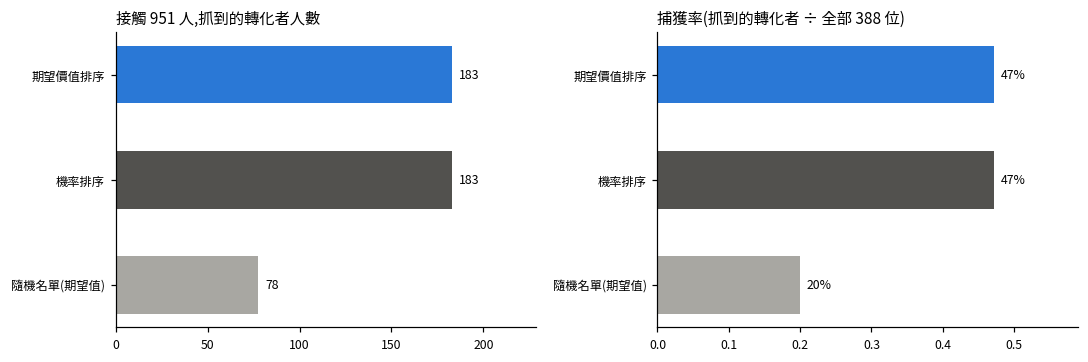

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
names = table_a.columns.tolist()
colors = [MAIN, REF, MUTED]
for ax, row, title, f in [(axes[0], "實際轉化人數", "接觸 951 人,抓到的轉化者人數", "{:.0f}"),
                          (axes[1], "捕獲率", "捕獲率(抓到的轉化者 ÷ 全部 388 位)", "{:.0%}")]:
    vals = table_a.loc[row].astype(float)
    ax.barh(names[::-1], vals[::-1], color=colors[::-1], height=0.55)
    for y, v in enumerate(vals[::-1]):
        ax.text(v + vals.max() * 0.02, y, f.format(v), va="center", fontsize=8)
    ax.set_xlim(0, vals.max() * 1.25)
    ax.set_title(title, loc="left", fontsize=10)
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**我的解讀**：

期望價值名單抓到了183位轉化者，名單轉化率:19.24%，捕獲率:47.2%。都是隨機名單（8.16%、20%）的 2.36 倍（Lift = 2.36），且多抓到 105.4 位轉化者。 而期望價值排序和機率排序相比，轉化人數相同，預估手續費高了40,237元（+10.1%，沒有做統計檢定，樣本只有 183 位轉化者，無法排除雜訊）。

證明:
名單能找到會自然轉化的人，成效是隨機名單的2.36倍

無法證明:
行銷有沒有作用，因為標籤是自然轉化的，這 183 人原本就會轉化，接觸他們不一定能增加新的轉化者，需要靠 C 層的 A/B 測試驗證。

## 2. B 層：每人年手續費（依推薦商品）

期望價值排序時還不知道客戶會買基金或 ETF，所以收入用「全部基金」「全部 ETF」的區間呈現。推薦完成後，可以依**實際推薦的商品**計算：

```
每人年手續費 = 核心金額 × 核心商品的費率係數 ＋ 衛星金額 × 衛星商品的費率係數
費率係數 = 12 × 申購費率 ＋ 6.5 × 經理費率（基金 0.2775、ETF 0.038）
```

- ETF：P03、P05、P09；其他為基金。
- **同分的客戶**（列出多檔商品讓客戶擇一）：用候選商品費率係數的**平均**。
- 「全部基金」「全部 ETF」保留作為參考區間。

In [5]:
def fee_factor(product):
    """推薦商品欄位 → 費率係數;同分時(例如 P01／P02／P03／P08)取候選商品的平均;沒有配置時為 0"""
    if pd.isna(product) or product == "":
        return 0.0
    codes = re.findall(r"P\d{2}", product)
    return np.mean([FEE_FACTOR["ETF" if p in ETF_PRODUCTS else "基金"] for p in codes])

recs["core_factor"] = recs["core_product"].map(fee_factor)
recs["satellite_factor"] = recs["satellite_product"].map(fee_factor)
recs["fee_by_product"] = recs["core_amount"] * recs["core_factor"] + recs["satellite_amount"] * recs["satellite_factor"]
recs["fee_all_fund"] = recs["sip"] * FEE_FACTOR["基金"]
recs["fee_all_etf"] = recs["sip"] * FEE_FACTOR["ETF"]

assert (recs["core_amount"] + recs["satellite_amount"] == recs["sip"]).all()
assert recs["core_factor"].gt(0).all()
assert (recs.loc[recs["satellite_amount"] > 0, "satellite_factor"] > 0).all()

is_etf = lambda col: recs[col].fillna("").isin(ETF_PRODUCTS)
etf_amount = recs["core_amount"] * is_etf("core_product") + recs["satellite_amount"] * is_etf("satellite_product")
FEE_COLS = {"依推薦商品(主要)": "fee_by_product", "全部基金": "fee_all_fund", "全部 ETF": "fee_all_etf"}
avg_fee = {name: recs[col].mean() for name, col in FEE_COLS.items()}
avg_sip = recs["sip"].mean()

print(f"平均月扣款:{avg_sip:,.0f} 元;配置在 ETF 的金額占比:{etf_amount.sum() / recs['sip'].sum():.1%}")
print(f"同分客戶:{recs['core_tie'].sum()} 人(費率係數取候選商品的平均)")
pd.DataFrame({"平均年手續費(元)": avg_fee,
              "接觸名單 951 人的總額(全部轉化時的上限)": {n: recs[c].sum() for n, c in FEE_COLS.items()}}).round(0)

平均月扣款:8,552 元;配置在 ETF 的金額占比:49.4%
同分客戶:1 人(費率係數取候選商品的平均)


,平均年手續費(元),接觸名單 951 人的總額(全部轉化時的上限)
依推薦商品(主要),1360.0,1293447.0
全部基金,2373.0,2256907.0
全部 ETF,325.0,309054.0


In [6]:
# ETF 金額的拆解:哪一檔 ETF 占最多、各 KYC 的 ETF 金額占比
amounts = pd.concat([recs[["kyc_risk_rating", "core_product", "core_amount"]].set_axis(["kyc", "product", "amount"], axis=1),
                     recs[["kyc_risk_rating", "satellite_product", "satellite_amount"]].set_axis(["kyc", "product", "amount"], axis=1)])
etf_rows = amounts[amounts["product"].isin(ETF_PRODUCTS)]
etf_by_product = etf_rows.groupby("product")["amount"].sum() / recs["sip"].sum()
print("各檔 ETF 占全部月扣款的比例:", {p: f"{v:.1%}" for p, v in etf_by_product.sort_values(ascending=False).items()},
      f"(合計 {etf_by_product.sum():.1%})")

KYC_ORDER = ["保守型", "穩健型", "積極型"]
by_kyc = recs.groupby("kyc_risk_rating")[list(FEE_COLS.values())].mean().reindex(KYC_ORDER)
by_kyc.columns = list(FEE_COLS)
by_kyc["ETF 金額占比"] = (etf_rows.groupby("kyc")["amount"].sum() / recs.groupby("kyc_risk_rating")["sip"].sum()).reindex(KYC_ORDER)
by_kyc["平均月扣款"] = recs.groupby("kyc_risk_rating")["sip"].mean().reindex(KYC_ORDER)
by_kyc.style.format({c: "{:,.0f}" for c in FEE_COLS} | {"ETF 金額占比": "{:.1%}", "平均月扣款": "{:,.0f}"})

各檔 ETF 占全部月扣款的比例: {'P09': '41.0%', 'P03': '5.4%', 'P05': '3.0%'} (合計 49.4%)


,依推薦商品(主要),全部基金,全部 ETF,ETF 金額占比,平均月扣款
kyc_risk_rating,,,,,
保守型,"2,173","2,452",336,13.1%,"8,837"
穩健型,"1,124","2,385",327,61.3%,"8,594"
積極型,947,"2,296",314,68.1%,"8,275"


**我的解讀**：

依推薦商品計算的平均年手續費為1,360元， 大約一半的錢放在 ETF、一半放在基金，所以落在中間附近。

ETF金額占比為49.4%，其中ETF的金額大多來自於P09(41.0%)，因為它是穩健型和積極型客戶最主要的核心商品，而核心占了月扣款的70%～80%。

三種 KYC 的平均年手續費比較在依推薦商品時有明顯差距，保守型2,173元最高，穩健型1,124元，而積極型947元最低。

全部基金／全部ETF時三種 KYC 沒有明顯差距，因為費率都一樣，只剩平均月扣款的小差異（8,837／8,594／8,275 元）。證明了KYC類型之間的差距來自推薦的商品，而不是來自扣款金額。

原先以為積極型客戶所帶來的手續費會是最多的，結果正好相反。
因為積極型的核心商品大多是低費率的ETF(P09)，
而保守型沒辦法買P09，核心大多使用基金

## 3. B 層：情境推估（假設）

標籤代表「沒有行銷介入的自然轉化」，所以模型無法直接證明行銷帶來多少**新增**轉化。「行銷使轉化率相對提升多少」沒有資料依據，所以用 **10%／20%／30%** 三個情境：

```
新增轉化客戶數 = 接觸人數 × 名單轉化率 × 行銷相對提升
新增手續費收入 = 新增轉化客戶數 × 每位轉化客戶的年手續費
第一年 AUM 流入 = 新增轉化客戶數 × 平均月扣款 × 12
```

- **名單轉化率**用 A 層 OOF 名單的結果（不用 `p_convert` 產生的接觸名單：那份名單是「模型看過答案」的分數排出來的）。
- **每位轉化客戶的年手續費**用接觸名單的平均，假設新增的客戶和名單整體相似。
- 公式對提升比例是**線性**的，所以先看「每提升 10%」的影響。
- 金額是**預估手續費收入**（毛收入），未扣除接觸成本；只算第一年。

In [7]:
def scenario(uplift):
    new_conv = TOP_N * list_rate * uplift
    row = {"新增轉化客戶": new_conv}
    row.update({f"新增手續費:{name}": new_conv * fee for name, fee in avg_fee.items()})
    row["第一年 AUM 流入"] = new_conv * avg_sip * 12
    return row

table_b = pd.DataFrame({f"提升 {u:.0%}": scenario(u) for u in UPLIFT_SCENARIOS}).T
print(f"名單轉化率(A 層 OOF):{list_rate:.2%};每提升 10% → 新增 {table_b.iloc[0, 0]:.1f} 位轉化客戶")
table_b.style.format({"新增轉化客戶": "{:.1f} 人"} | {c: "{:,.0f}" for c in table_b.columns[1:]})

名單轉化率(A 層 OOF):19.24%;每提升 10% → 新增 18.3 位轉化客戶


,新增轉化客戶,新增手續費:依推薦商品(主要),新增手續費:全部基金,新增手續費:全部 ETF,第一年 AUM 流入
提升 10%,18.3 人,"24,890","43,429","5,947","1,878,030"
提升 20%,36.6 人,"49,779","86,859","11,894","3,756,061"
提升 30%,54.9 人,"74,669","130,288","17,841","5,634,091"


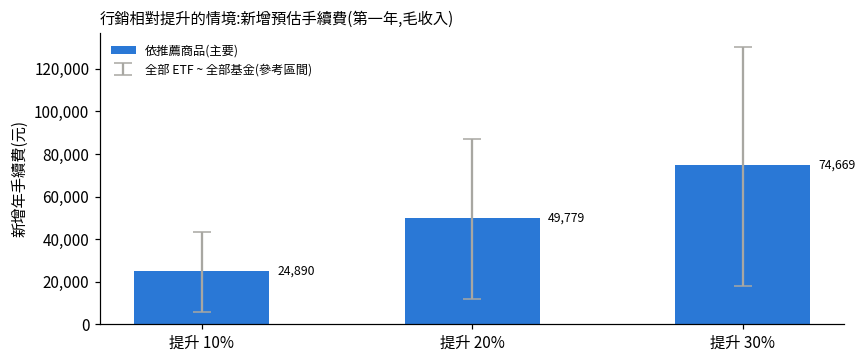

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(UPLIFT_SCENARIOS))
main = table_b["新增手續費:依推薦商品(主要)"]
low, high = table_b["新增手續費:全部 ETF"], table_b["新增手續費:全部基金"]
ax.bar(x, main, color=MAIN, width=0.5, label="依推薦商品(主要)")
ax.errorbar(x, main, yerr=[main - low, high - main], fmt="none", ecolor=MUTED, capsize=6, lw=1.5,
            label="全部 ETF ~ 全部基金(參考區間)")
for i, v in enumerate(main):
    ax.text(i + 0.28, v, f"{v:,.0f}", va="center", fontsize=8)
ax.set_xticks(x, [f"提升 {u:.0%}" for u in UPLIFT_SCENARIOS])
ax.set_ylabel("新增年手續費(元)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("行銷相對提升的情境:新增預估手續費(第一年,毛收入)", loc="left", fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**我的解讀**：


轉化率每提升10%，新增18.3位客戶，24,890元手續費，第一年 AUM 流入 1,878,030 元

為什麼手續費和 AUM 的量級差這麼多？

AUM 是客戶的錢，手續費是銀行從這筆錢裡抽的一小部分，每位客戶的年手續費只有第一年 AUM 流入的約 1.3%。原因有三個：

① 手續費是百分比：基金的申購費和經理費都只有 1.5%，ETF 更低（0.1%、0.4%）

② 大約一半的錢放在低費率的 ETF（ETF 金額占比 49.4%）

③ 只算第一年，而且經理費依「平均餘額」收：定期定額每個月才扣一次，第一年的平均餘額只有月扣款的 6.5 倍，不是 12 倍。

但 AUM 是逐年累積的，經理費每年都會收取，所以第一年的手續費只是起點，定期定額的價值在於穩定、經常性的收入。


提升比例有什麼根據:

沒有根據，因為標籤是自然轉化的，資料裡沒有任何行銷效果的資訊。

所以沒有給一個數字，而是以每提升10%，會新增 18 位客戶、約 2.5 萬元手續費作為換算單位，也可以自行換成其他比例。

真正的提升比例要靠 A/B 測試量出來：把名單隨機分成接觸組和保留組，兩組轉化率的差距就是答案，再代回公式就好。

## 4. C 層：上線驗證計畫

B 層的「行銷相對提升」沒有資料依據，要靠上線後的 A/B 測試量出來（計畫書 1.5）：

| 項目 | 設計 |
| --- | --- |
| 對象 | 期望價值排序的前 20%（可推薦客戶 4,755 人中的 951 人） |
| 分組 | 隨機分成「接觸組」（收到推播與配置建議）與「保留組」（不接觸） |
| 觀察期 | 3 個月，與標籤期一致 |
| 主要指標 | 兩組的定期定額開始率差異（行銷帶來的增量） |
| 次要指標 | 平均月扣款金額、3 個月後的續扣率 |
| 判斷方式 | 接觸組的開始率顯著高於保留組，才代表策略有效；若沒有差異，代表高分客戶本來就會自己轉化，行銷資源應該轉移到其他客群 |

**三層的關係**：A 層證明名單找得到會轉化的人；B 層假設行銷能讓轉化率提升 X%；C 層的 A/B 測試量出來的「接觸組 ÷ 保留組 − 1」，就是 B 層 X 的實際值。量到之後，把它代回 B 層的公式，就能得到實際的新增手續費。

## 總結

| 層 | 項目 | 結果 | 實測／假設 |
| --- | --- | --- | --- |
| A | 名單效率 | 期望價值名單抓到了183位轉化者、名單轉化率:19.24%、捕獲率:47.2%。都是隨機名單（8.16%、20%）的 2.36 倍；多抓到 105.4 位轉化者。| 實測 |
| A | 期望價值排序 vs 機率排序 | 轉化人數相同，預估手續費高了40,237元（+10.1%，沒有做統計檢定，樣本只有 183 位轉化者，無法排除雜訊）| 實測 |
| B | 每人年手續費 | 依推薦商品計算為1,360元，介於全部 ETF 325 元和全部基金 2,373 元之間；原因:ETF金額占比為49.4%，大多來自於P09(41.0%)。KYC類型差距:保守型 2,173元最高、穩健型 1,124元、積極型 947 元最低 | 假設（費率） |
| B | 情境推估 | 每提升10%:新增18.3位客戶，24,890元手續費，第一年 AUM 流入約188萬元。10%／20%／30% 三個情境呈線性| 假設（提升比例） |
| C | 驗證計畫 | A/B 測試（接觸組 vs 保留組，觀察 3 個月），兩組轉化率的差距就是 B 層的提升比例 | — |
| 限制 | | ① A 層證明名單找得到會自然轉化的人，但無法證明行銷有效 ② 行銷提升比例沒有資料依據，B 層全部是假設 ③ 只算第一年，低估了 AUM 累積帶來的長期價值；也假設客戶整年持續扣款、不考慮投資報酬 ④ 金額是毛收入，沒有扣除接觸成本 ⑤ 用接觸名單的平均年手續費代表新增客戶，但新增的客戶不一定和名單整體相似 ⑥ 期望價值 vs 機率排序的 +10.1% 沒有做統計檢定，樣本只有 183 位轉化者 | |
| 下一步 | | README 與收尾 | |